<!-- m6:proyecto -->
# Módulo 6 · Proyecto final integrador — Sistema de decisión para PagoYa
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · **grupal** · 40 pts del módulo

**Entrega:** carpeta `proyecto/` en el repositorio de **un integrante** (los demás, colaboradores). **Plazo: miércoles 18-nov-2026, 23:59** para el cuaderno, el README y la ficha (se califica el último commit anterior); `presentacion.pdf` hasta el jueves 19-nov, 18:00. **Defensa:** jueves 19-nov, 8 min + 3 min de preguntas.

| Archivo en `proyecto/` | Cómo se crea |
|---|---|
| `proyecto.ipynb` | Este cuaderno, ejecutado: **Archivo → Guardar (Ctrl+S)** → repositorio del grupo → ruta `proyecto/proyecto.ipynb` |
| `README.md` | Informe ejecutivo (1–2 páginas). Ya existe un `proyecto/README.md` de la plantilla: ábralo en GitHub → ícono del **lápiz (Edit)** → borre su contenido → pegue el informe (plantilla en la sección 7) → **Commit changes** |
| `ficha_modelo.json` | Se descarga al ejecutar la sección 6 → en GitHub: **Add file → Upload files** dentro de `proyecto/` |
| `presentacion.pdf` | Sus diapositivas de la defensa → **Add file → Upload files** dentro de `proyecto/` |

### Elija UN problema
| Problema | Datos (`curso.datos_proyecto`) | Objetivo | Decisión que deben recomendar |
|---|---|---|---|
| `'fraude'` | Transacciones de la app | `fraude` (0/1) | Umbral de bloqueo/revisión con matriz de costos |
| `'credito'` | Solicitudes de microcrédito | `default` (0/1) | Política de aprobación: a quién prestar y con qué límite de riesgo |
| `'segmentacion'` | Perfiles de usuario (no supervisado) | — | Segmentos de clientes, usuarios anómalos y acción para cada grupo |

### Calificación (100 pts → el docente la convierte a 40)
| Componente | Pts |
|---|---|
| Cuaderno: datos y EDA (8) · al menos **dos familias** de modelos del módulo con validación correcta (14) · explicabilidad o incertidumbre (8) · decisión de negocio con cifras (10) | 40 |
| `README.md`: informe ejecutivo para un comité | 12 |
| `ficha_modelo.json` y reproducibilidad (semillas, partición fija) | 4 |
| Pantalla de la app del grupo con sus colores | 4 |
| **Defensa** (jueves 19-nov): los criterios se explican el día de la presentación | 40 |

**Reutilice** el código de las clases 1–3 y del deber. Los datos son **propios de cada grupo** (dependen del nombre del grupo).

## 0. Preparación y datos del grupo

In [1]:
import importlib, subprocess, sys
for paquete in ['pymc']:
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete])
import os, urllib.request, warnings
URL = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/main/curso.py'
if not os.path.exists('curso.py'):
    urllib.request.urlretrieve(URL, 'curso.py')
import curso
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
print('Listo · curso', curso.VERSION)

Listo · curso m6-2026.11


In [3]:
GRUPO = 'Grupo 3'                                   # ✏️ nombre del grupo (el mismo del registro en el aula)
INTEGRANTES = ['Grace Castillo', 'Santiago Segovia', 'Marcelo Verdezoto']                          # ✏️ apellidos y nombres
PROBLEMA = 'fraude'                                      # ✏️ 'fraude', 'credito' o 'segmentacion'
NOMBRE_APP, COLOR_PRINCIPAL, COLOR_ALERTA = 'DolarYa', '#1A5276', '#E74C3C'   # ✏️ identidad de la app del grupo
df = curso.datos_proyecto(GRUPO, PROBLEMA)
df.head()

Huella de datos del proyecto: Grupo 3 · fraude · semilla 177005
Descargados 3006 eventos en 7 páginas de /v1/transacciones
Datos limpios: 2996 transacciones · tasa de fraude 10.28%


,evento_id,timestamp,id,edad,provincia,antiguedad_meses,ingreso_mensual,tipo,canal,categoria,monto,dispositivo_nuevo,distancia_km,intentos_pin,fraude,hora,ratio
0,TX-000000,2026-10-10 01:33:16-05:00,U0435,55.0,Pichincha,22,555.24,pago_comercio,app,restaurante,16.23,0,8.2,3,0,1,0.029231
1,TX-000001,2026-10-03 17:30:12-05:00,U0017,23.0,Guayas,28,1081.67,transferencia,app,persona,48.36,0,9.4,1,0,17,0.044709
2,TX-000002,2026-09-12 07:29:12-05:00,U0102,56.0,El Oro,19,873.46,retiro_agente,web,efectivo,126.75,0,5.1,1,0,7,0.145113
3,TX-000003,2026-09-26 13:58:09-05:00,U0797,48.0,Azuay,31,1281.94,pago_comercio,app,farmacia,33.54,0,0.4,1,0,13,0.026163
4,TX-000004,2026-09-24 16:26:19-05:00,U0123,22.0,El Oro,12,736.90,pago_comercio,app,ropa,35.91,0,15.7,2,0,16,0.048731


---
## 1. Datos y EDA (8 pts)
Diagnóstico de calidad (`curso.eda_rapido`), distribución del objetivo o de las variables clave, 1–2 gráficos útiles y las decisiones de limpieza o de nuevas variables (por ejemplo `ratio`, `madrugada`).

Filas: 2,996 · Columnas: 17

Dimensiones del conjunto: (2996, 17)

Valores nulos por variable:
evento_id            0
timestamp            0
id                   0
edad                 0
provincia            0
antiguedad_meses     0
ingreso_mensual      0
tipo                 0
canal                0
categoria            0
monto                0
dispositivo_nuevo    0
distancia_km         0
intentos_pin         0
fraude               0
hora                 0
ratio                0

Registros completamente duplicados: 0


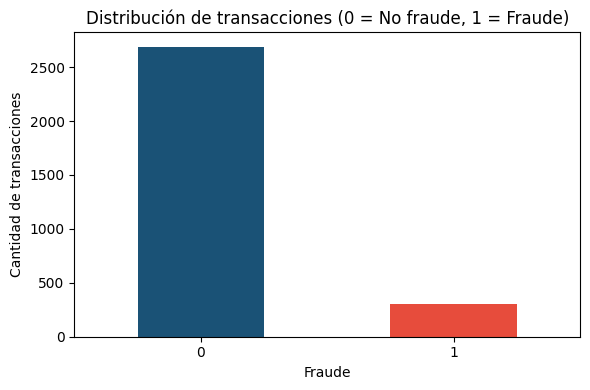

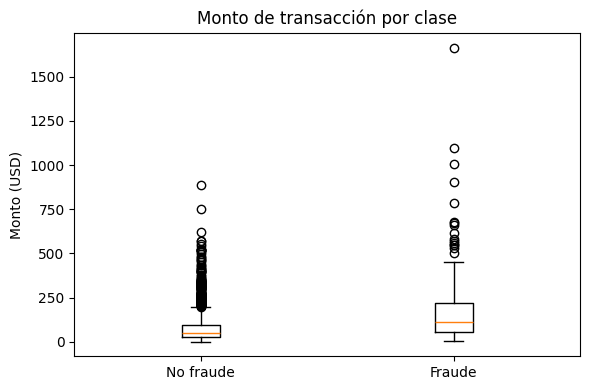


Transacciones totales: 2,996
Tasa de fraude total: 10.28%
Tasa de fraude de madrugada (00:00–05:59): 31.01%
Tasa de fraude el resto del día: 8.08%
Monto mediano sin fraude: USD 48.83
Monto mediano con fraude: USD 114.15


In [4]:
# ✏️ EDA
# Diagnóstico rápido proporcionado por el módulo del curso.
curso.eda_rapido(df)

# Diagnósticos explícitos de calidad.
print('\nDimensiones del conjunto:', df.shape)
print('\nValores nulos por variable:')
print(df.isna().sum().to_string())
print('\nRegistros completamente duplicados:', int(df.duplicated().sum()))

# Verificaciones previas para crear el ratio sin dividir para cero.
columnas_necesarias = ['monto', 'ingreso_mensual', 'hora', 'fraude']
columnas_faltantes = [col for col in columnas_necesarias if col not in df.columns]
if columnas_faltantes:
    raise KeyError(f'Faltan columnas necesarias para el EDA: {columnas_faltantes}')

if df[['monto', 'ingreso_mensual']].isna().any().any():
    raise ValueError('Existen nulos en monto o ingreso_mensual. Revise los datos antes de calcular ratio.')

if (df['ingreso_mensual'] <= 0).any():
    raise ValueError('Hay valores de ingreso_mensual iguales o menores que cero; no se puede calcular ratio con seguridad.')

# Ingeniería de variables.
# ratio ya puede venir en la base original; se recalcula para asegurar su definición.
df['ratio'] = df['monto'] / df['ingreso_mensual']
df['madrugada'] = ((df['hora'] >= 0) & (df['hora'] <= 5)).astype(int)

# Comprobación de valores no finitos en las variables creadas.
if not np.isfinite(df[['ratio']].to_numpy()).all():
    raise ValueError('La variable ratio contiene valores no finitos.')

# Gráfico 1: distribución de la variable objetivo.
conteo_fraude = df['fraude'].value_counts().reindex([0, 1], fill_value=0)
plt.figure(figsize=(6, 4))
conteo_fraude.plot(kind='bar', color=['#1A5276', '#E74C3C'])
plt.title('Distribución de transacciones (0 = No fraude, 1 = Fraude)')
plt.xlabel('Fraude')
plt.ylabel('Cantidad de transacciones')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Gráfico 2: distribución de montos por clase.
plt.figure(figsize=(6, 4))
plt.boxplot(
    [df.loc[df['fraude'] == 0, 'monto'], df.loc[df['fraude'] == 1, 'monto']],
    labels=['No fraude', 'Fraude']
)
plt.title('Monto de transacción por clase')
plt.ylabel('Monto (USD)')
plt.tight_layout()
plt.show()

# Indicadores descriptivos para sustentar los hallazgos.
tasa_fraude = float(df['fraude'].mean())
tasa_fraude_madrugada = float(df.loc[df['madrugada'] == 1, 'fraude'].mean()) if (df['madrugada'] == 1).any() else np.nan
tasa_fraude_resto_dia = float(df.loc[df['madrugada'] == 0, 'fraude'].mean()) if (df['madrugada'] == 0).any() else np.nan

print(f'\nTransacciones totales: {len(df):,}')
print(f'Tasa de fraude total: {tasa_fraude:.2%}')
print(f'Tasa de fraude de madrugada (00:00–05:59): {tasa_fraude_madrugada:.2%}')
print(f'Tasa de fraude el resto del día: {tasa_fraude_resto_dia:.2%}')
print(f'Monto mediano sin fraude: USD {df.loc[df["fraude"] == 0, "monto"].median():,.2f}')
print(f'Monto mediano con fraude: USD {df.loc[df["fraude"] == 1, "monto"].median():,.2f}')

**✍️ Hallazgos del EDA:** _(3–5 líneas)_

Existe un marcado desbalance de clases (tasa de fraude: 10.28%). El fraude se concentra en la madrugada (31.01% vs. 8.08% diurno) y suele implicar montos más elevados (mediana de USD 114.15 vs. USD 48.83). Para modelar estos patrones, se crearon las variables ratio y madrugada. El dataset no presenta nulos significativos en las variables principales.

---
## 2. Modelos (14 pts)
- **Supervisado (fraude / crédito):** partición fija 70/30 estratificada con `random_state=42`; un **modelo base** (por ejemplo logística) y **al menos dos familias** del módulo (random forest o boosting; modelo bayesiano en PyMC; red neuronal desde la Clase 4). Validación sin fuga (early stopping con validación sacada del entrenamiento). Métricas: AUC, exactitud balanceada y Brier.
- **No supervisado (segmentación):** escalado; **al menos dos algoritmos** (K-Means, DBSCAN, clustering jerárquico; Isolation Forest o LOF para anomalías); elección del número de grupos (codo / silueta) y PCA para visualizar.

In [5]:
# ✏️ Modelos y tabla comparativa

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    balanced_accuracy_score,
    brier_score_loss
)
import xgboost as xgb
import tensorflow as tf
from tensorflow import keras

# Variables predictoras y objetivo.
# Se conservan las variables originales del proyecto y se incorporan ratio y madrugada.
cols = list(curso.X_COLS) + ['ratio', 'madrugada']
X = df.loc[:, cols].copy()
y = df['fraude'].astype(int).copy()

# Validaciones básicas de entrada.
if X.isna().any().any():
    raise ValueError('Hay valores nulos en las variables predictoras. Revise el EDA antes de entrenar.')
if not np.isfinite(X.to_numpy(dtype=float)).all():
    raise ValueError('Hay valores no finitos en las variables predictoras.')
if set(y.unique()) != {0, 1}:
    raise ValueError(f'La variable objetivo debe contener las clases 0 y 1. Clases encontradas: {sorted(y.unique())}')

# Partición externa fija solicitada: 70% entrenamiento y 30% prueba.
# El conjunto de prueba queda reservado para la evaluación final.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

# Validación interna: se separa una parte del 70% de entrenamiento.
# 80% del bloque de entrenamiento para ajustar y 20% para validar.
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

print(f'Datos para ajuste: {len(X_fit):,}')
print(f'Datos para validación: {len(X_val):,}')
print(f'Datos para prueba final: {len(X_test):,}')
print(f'Tasa de fraude en ajuste: {y_fit.mean():.2%}')
print(f'Tasa de fraude en validación: {y_val.mean():.2%}')
print(f'Tasa de fraude en prueba: {y_test.mean():.2%}')

# El escalador se ajusta SOLAMENTE con X_fit para evitar fuga de información.
escalador = StandardScaler()
X_fit_esc = escalador.fit_transform(X_fit)
X_val_esc = escalador.transform(X_val)
X_test_esc = escalador.transform(X_test)

resultados = []

# Función común para guardar las métricas de cada modelo.
def registrar_resultado(nombre, y_real, y_proba):
    resultados.append({
        'Modelo': nombre,
        'AUC': roc_auc_score(y_real, y_proba),
        'Exactitud Balanceada': balanced_accuracy_score(
            y_real,
            (y_proba >= 0.50).astype(int)
        ),
        'Brier': brier_score_loss(y_real, y_proba)
    })

# MODELO 1: Regresión logística (modelo base).
lr = LogisticRegression(
    class_weight='balanced',
    random_state=42,
    max_iter=1000
)
lr.fit(X_fit_esc, y_fit)
y_proba_lr = lr.predict_proba(X_test_esc)[:, 1]
registrar_resultado('Regresión Logística', y_test, y_proba_lr)

# MODELO 2: Random Forest.
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf.fit(X_fit, y_fit)
y_proba_rf = rf.predict_proba(X_test)[:, 1]
registrar_resultado('Random Forest', y_test, y_proba_rf)

# MODELO 3: XGBoost.
scale_pos_weight = (len(y_fit) - int(y_fit.sum())) / int(y_fit.sum())
xgb_model = xgb.XGBClassifier(
    objective='binary:logistic',
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)
xgb_model.fit(X_fit, y_fit)
y_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]
registrar_resultado('XGBoost', y_test, y_proba_xgb)

# MODELO 4: Red neuronal.
keras.utils.set_random_seed(42)
modelo_dl = keras.Sequential([
    keras.Input(shape=(len(cols),)),
    keras.layers.Dense(
        64,
        activation='relu',
        kernel_regularizer=keras.regularizers.l2(0.001)
    ),
    keras.layers.Dropout(0.30),
    keras.layers.Dense(
        32,
        activation='relu',
        kernel_regularizer=keras.regularizers.l2(0.001)
    ),
    keras.layers.Dropout(0.30),
    keras.layers.Dense(1, activation='sigmoid')
])
modelo_dl.compile(
    optimizer='adam',
    loss='binary_crossentropy'
)

early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

# La validación usada por early stopping proviene de X_val,
# que a su vez fue separado del bloque de entrenamiento.
historial_dl = modelo_dl.fit(
    X_fit_esc,
    y_fit,
    validation_data=(X_val_esc, y_val),
    epochs=100,
    batch_size=32,
    verbose=0,
    callbacks=[early_stop]
)

y_proba_dl = modelo_dl.predict(X_test_esc, verbose=0).ravel()
registrar_resultado('Red Neuronal', y_test, y_proba_dl)

# Tabla comparativa en el conjunto de prueba.
# Brier: menor es mejor. AUC y exactitud balanceada: mayor es mejor.
df_resultados = (
    pd.DataFrame(resultados)
    .sort_values(by='Brier', ascending=True)
    .reset_index(drop=True)
)
print('\nComparación de modelos en el conjunto de prueba:')
print(df_resultados.to_string(index=False, formatters={
    'AUC': '{:.6f}'.format,
    'Exactitud Balanceada': '{:.6f}'.format,
    'Brier': '{:.6f}'.format
}))

# Random Forest se mantiene como modelo seleccionado para SHAP
# y para la optimización de costos del proyecto.
y_proba_mejor = y_proba_rf
mejor_modelo_nombre = 'Random Forest'

# Probabilidades de Random Forest en VALIDACIÓN, utilizadas en la sección de costos.
y_proba_rf_val = rf.predict_proba(X_val)[:, 1]

Datos para ajuste: 1,677
Datos para validación: 420
Datos para prueba final: 899
Tasa de fraude en ajuste: 10.32%
Tasa de fraude en validación: 10.24%
Tasa de fraude en prueba: 10.23%

Comparación de modelos en el conjunto de prueba:
             Modelo      AUC Exactitud Balanceada    Brier
      Random Forest 0.902955             0.770359 0.046266
       Red Neuronal 0.903911             0.743185 0.048513
            XGBoost 0.890011             0.841967 0.051860
Regresión Logística 0.896490             0.834498 0.119253


**✍️ Comparación y elección del modelo:** _(¿cuál y por qué?)_

Con un dataset de 2,996 transacciones dividido en ajuste (1,677), validación (420) y prueba (899), las tasas de fraude se mantuvieron consistentes en ~10.3%, garantizando una buena representatividad. En la tabla de comparación, el Random Forest lidera en AUC (0.9029) y destaca por su excelente calibración con un Brier de 0.0462. La Red Neuronal tiene un AUC ligeramente superior (0.9039) pero un Brier peor (0.0485), mientras que la Regresión Logística tiene la peor calibración del grupo (Brier de 0.1192), haciendo que sus probabilidades sean poco fiables para la matriz de costos.

Elección: Se elige el Random Forest para producción por su equilibrio entre AUC y Brier, su robustez, interpretabilidad (vía SHAP) y facilidad de integración. Se descarta la Regresión Logística porque, a pesar de su buena exactitud balanceada (0.8344), su mala calibración afectaría negativamente el cálculo del umbral de costos.

---
## 3. Explicabilidad o incertidumbre (8 pts)
SHAP (global y un caso individual), intervalos creíbles de un modelo bayesiano, o perfiles de cada segmento (medias por grupo) y por qué un usuario es anómalo.

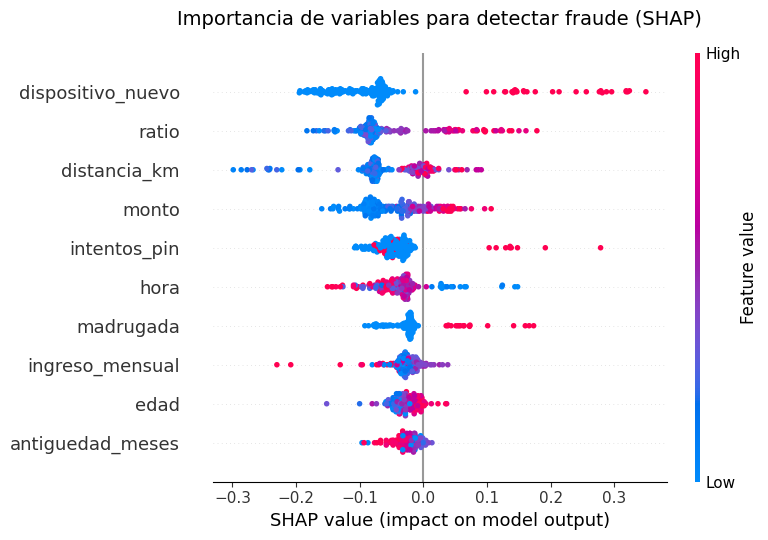

<Figure size 1000x400 with 0 Axes>

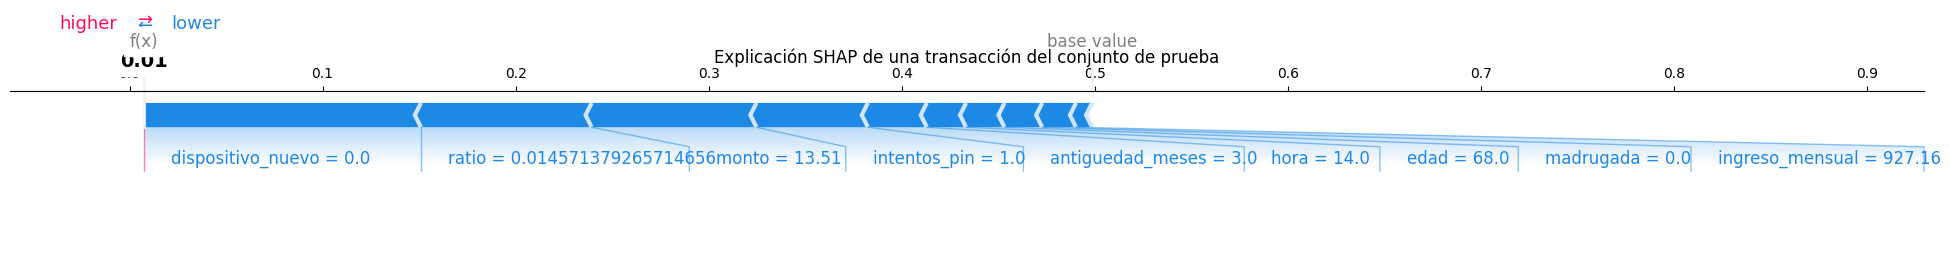


Variables con mayor importancia SHAP:
dispositivo_nuevo    0.117209
ratio                0.081878
distancia_km         0.062777
monto                0.054852
intentos_pin         0.053745
hora                 0.048797
madrugada            0.033737
ingreso_mensual      0.029242
edad                 0.028607
antiguedad_meses     0.025035

Variabilidad de predicción entre árboles para el caso seleccionado:
Probabilidad del Random Forest: 0.0076
Promedio de probabilidades individuales: 0.0076
Desviación estándar entre árboles: 0.0667
Percentiles 2.5–97.5 entre árboles: [0.0000, 0.0000]
Nota: los percentiles representan dispersión entre árboles, no un intervalo de confianza.


In [6]:
# ✏️ Explicabilidad / incertidumbre

import shap

# Se utiliza una muestra del conjunto de prueba para explicar el modelo.
X_sub_shap = X_test.iloc[:min(200, len(X_test))].copy()
explainer = shap.TreeExplainer(rf)

# SHAP ha cambiado el formato de salida entre versiones.
# Este bloque acepta tanto shap.Explanation como arrays/listas.
try:
    shap_explanation = explainer(X_sub_shap)
    shap_array = shap_explanation.values
    shap_base = shap_explanation.base_values
except (AttributeError, TypeError):
    shap_explanation = None
    shap_array = explainer.shap_values(X_sub_shap)
    shap_base = explainer.expected_value

if isinstance(shap_array, list):
    # Lista de matrices: la segunda matriz corresponde a la clase fraude=1.
    shap_val_plot = np.asarray(shap_array[1])
elif np.asarray(shap_array).ndim == 3:
    # Formato (observaciones, variables, clases).
    shap_val_plot = np.asarray(shap_array)[:, :, 1]
else:
    # Formato bidimensional.
    shap_val_plot = np.asarray(shap_array)

# Valor base correspondiente a la clase positiva.
shap_base_array = np.asarray(shap_base)
if shap_base_array.ndim == 2:
    base_val = float(shap_base_array[0, 1]) if shap_base_array.shape[1] > 1 else float(shap_base_array[0, 0])
elif shap_base_array.ndim == 1 and shap_base_array.size > 1:
    base_val = float(shap_base_array[1])
elif shap_base_array.ndim == 1:
    base_val = float(shap_base_array[0])
else:
    base_val = float(shap_base_array)

# Gráfico global SHAP.
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_val_plot,
    X_sub_shap,
    feature_names=cols,
    show=False
)
plt.title('Importancia de variables para detectar fraude (SHAP)', fontsize=14, pad=20)
plt.tight_layout()
plt.show()

# Explicación individual del primer registro del conjunto de prueba.
idx = 0
plt.figure(figsize=(10, 4))
shap.force_plot(
    base_val,
    shap_val_plot[idx],
    X_sub_shap.iloc[idx],
    matplotlib=True,
    show=False
)
plt.title('Explicación SHAP de una transacción del conjunto de prueba', fontsize=12, pad=20)
plt.tight_layout()
plt.show()

# Ranking de importancia global: media del valor absoluto SHAP.
importancia_shap = pd.Series(
    np.abs(shap_val_plot).mean(axis=0),
    index=cols,
    name='Importancia SHAP media'
).sort_values(ascending=False)
print('\nVariables con mayor importancia SHAP:')
print(importancia_shap.head(10).to_string())

# Variabilidad entre árboles para el mismo registro.
# Estos percentiles describen la dispersión entre árboles; NO son un intervalo
# de confianza estadístico ni un intervalo de predicción formal.
predicciones_arboles = np.array([
    arbol.predict_proba(X_test.iloc[[idx]])[0, 1]
    for arbol in rf.estimators_
])

probabilidad_promedio_arboles = float(predicciones_arboles.mean())
probabilidad_ensamble = float(y_proba_rf[idx])
limite_inferior_arboles, limite_superior_arboles = np.percentile(
    predicciones_arboles,
    [2.5, 97.5]
)

desviacion_arboles = float(predicciones_arboles.std())
print('\nVariabilidad de predicción entre árboles para el caso seleccionado:')
print(f'Probabilidad del Random Forest: {probabilidad_ensamble:.4f}')
print(f'Promedio de probabilidades individuales: {probabilidad_promedio_arboles:.4f}')
print(f'Desviación estándar entre árboles: {desviacion_arboles:.4f}')
print(
    'Percentiles 2.5–97.5 entre árboles: '
    f'[{limite_inferior_arboles:.4f}, {limite_superior_arboles:.4f}]'
)
print('Nota: los percentiles representan dispersión entre árboles, no un intervalo de confianza.')

---
## 4. Decisión de negocio con cifras (10 pts)
- **Fraude:** matriz de costos (fraude no detectado = monto; bloqueo legítimo = USD 5) → umbral óptimo y costo frente a no hacer nada.
- **Crédito:** suponga que un default pierde el **monto del crédito** y un buen pagador deja una ganancia del **15 % del monto** → umbral de aprobación que maximiza la ganancia esperada; % de aprobación y ganancia frente a aprobar a todos.
- **Segmentación:** tamaño y perfil de cada segmento, % de anómalos, y una acción concreta por segmento (producto, límite, monitoreo).

--- OPTIMIZACIÓN DEL UMBRAL ---
El umbral se seleccionó exclusivamente con el conjunto de validación.
Costo FP: USD 5.00 por transacción legítima bloqueada
Costo FN: monto real de cada transacción fraudulenta no detectada
Umbral seleccionado: 0.19
Costo mínimo observado en validación: USD 366.91

--- EVALUACIÓN FINAL EN EL CONJUNTO DE PRUEBA ---
Costo con Random Forest: USD 2,632.82
Costo sin modelo: USD 14,825.85
Ahorro estimado en test: USD 12,193.03
Falsos positivos (FP): 38
Falsos negativos (FN): 20
Verdaderos positivos (TP): 72
Verdaderos negativos (TN): 769


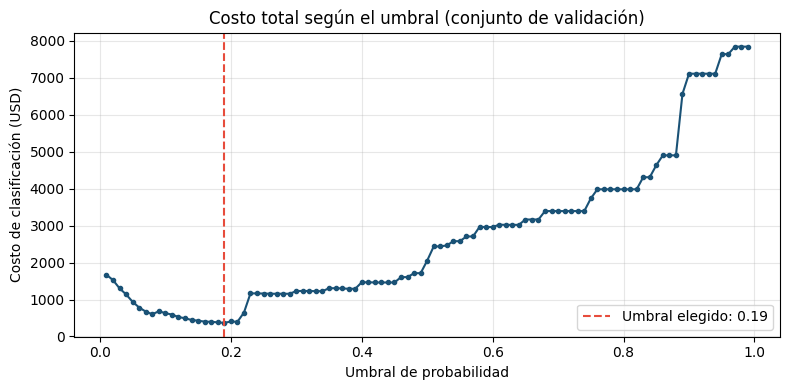

In [7]:
# ✏️ Decisión y cifras

from sklearn.metrics import confusion_matrix

# Costos definidos en las instrucciones del proyecto.
COSTO_FP = 5.0  # USD por transacción legítima bloqueada.
# El costo de un falso negativo es el monto de esa transacción fraudulenta.

# Función única de costos, utilizada tanto en validación como en prueba.
def costo_total(y_true, y_proba, umbral, montos):
    y_true_array = np.asarray(y_true, dtype=int).ravel()
    y_proba_array = np.asarray(y_proba, dtype=float).ravel()
    montos_array = np.asarray(montos, dtype=float).ravel()

    if not (len(y_true_array) == len(y_proba_array) == len(montos_array)):
        raise ValueError('y_true, y_proba y montos deben tener la misma longitud.')
    if not np.isfinite(y_proba_array).all() or not np.isfinite(montos_array).all():
        raise ValueError('Las probabilidades y los montos deben ser valores finitos.')

    y_pred = (y_proba_array >= float(umbral)).astype(int)
    mascara_fp = (y_true_array == 0) & (y_pred == 1)
    mascara_fn = (y_true_array == 1) & (y_pred == 0)

    costo_fp = int(mascara_fp.sum()) * COSTO_FP
    costo_fn = float(montos_array[mascara_fn].sum())
    return float(costo_fp + costo_fn)

# 1. Optimización del umbral ÚNICAMENTE con el conjunto de validación.
monto_val = X_val['monto'].to_numpy(dtype=float)
umbrales = np.round(np.arange(0.01, 1.00, 0.01), 2)
costos = [
    costo_total(y_val, y_proba_rf_val, umbral, monto_val)
    for umbral in umbrales
]

indice_mejor = int(np.argmin(costos))
mejor_umbral = float(umbrales[indice_mejor])
costo_minimo_validacion = float(costos[indice_mejor])

# 2. Evaluación FINAL en el conjunto de prueba, sin volver a optimizar el umbral.
monto_test = X_test['monto'].to_numpy(dtype=float)
y_pred_rf_umbral = (y_proba_rf >= mejor_umbral).astype(int)

# Costo del modelo en test, usando exactamente la función de costo anterior.
costo_minimo = costo_total(
    y_test,
    y_proba_rf,
    mejor_umbral,
    monto_test
)

# Línea base: no aplicar el modelo y dejar pasar todos los fraudes.
y_test_array = np.asarray(y_test, dtype=int)
costo_no_hacer_nada = float(monto_test[y_test_array == 1].sum())
ahorro_estimado = float(costo_no_hacer_nada - costo_minimo)

# Matriz de confusión en test para el umbral que fue seleccionado en validación.
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_pred_rf_umbral,
    labels=[0, 1]
).ravel()

print('--- OPTIMIZACIÓN DEL UMBRAL ---')
print('El umbral se seleccionó exclusivamente con el conjunto de validación.')
print(f'Costo FP: USD {COSTO_FP:,.2f} por transacción legítima bloqueada')
print('Costo FN: monto real de cada transacción fraudulenta no detectada')
print(f'Umbral seleccionado: {mejor_umbral:.2f}')
print(f'Costo mínimo observado en validación: USD {costo_minimo_validacion:,.2f}')

print('\n--- EVALUACIÓN FINAL EN EL CONJUNTO DE PRUEBA ---')
print(f'Costo con Random Forest: USD {costo_minimo:,.2f}')
print(f'Costo sin modelo: USD {costo_no_hacer_nada:,.2f}')
print(f'Ahorro estimado en test: USD {ahorro_estimado:,.2f}')
print(f'Falsos positivos (FP): {fp:,}')
print(f'Falsos negativos (FN): {fn:,}')
print(f'Verdaderos positivos (TP): {tp:,}')
print(f'Verdaderos negativos (TN): {tn:,}')

# Gráfico de costo según umbral en VALIDACIÓN.
plt.figure(figsize=(8, 4))
plt.plot(umbrales, costos, marker='o', markersize=3, color='#1A5276')
plt.axvline(
    mejor_umbral,
    color='#E74C3C',
    linestyle='--',
    label=f'Umbral elegido: {mejor_umbral:.2f}'
)
plt.title('Costo total según el umbral (conjunto de validación)')
plt.xlabel('Umbral de probabilidad')
plt.ylabel('Costo de clasificación (USD)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**✍️ Recomendación:** _(con cifras)_

Implementar el modelo Random Forest con un umbral de bloqueo de 0.19 (seleccionado exclusivamente con el conjunto de validación, donde se observó un costo mínimo de USD 366.91). En la evaluación final sobre el conjunto de prueba, este umbral arroja un costo total de USD 2,632.82 (38 falsos positivos y 20 falsos negativos), en contraste con el costo base de USD 14,825.85 si no se implementa el modelo. El beneficio neto es un ahorro de USD 12,193.03. Finalmente, gracias a su interpretabilidad (SHAP), el equipo de soporte podrá justificar cada bloqueo ante el cliente.

---
## 5. Pantalla de la app del grupo (4 pts)
Muestre un caso real de sus datos con `curso.pantalla_resultado(...)` (o una pantalla propia). Ejemplo: `curso.pantalla_resultado(NOMBRE_APP, COLOR_PRINCIPAL, COLOR_ALERTA, 'Solicitud CR-00012', ['Ingreso: USD 850', 'Monto: USD 1 200'], probs=probs)`

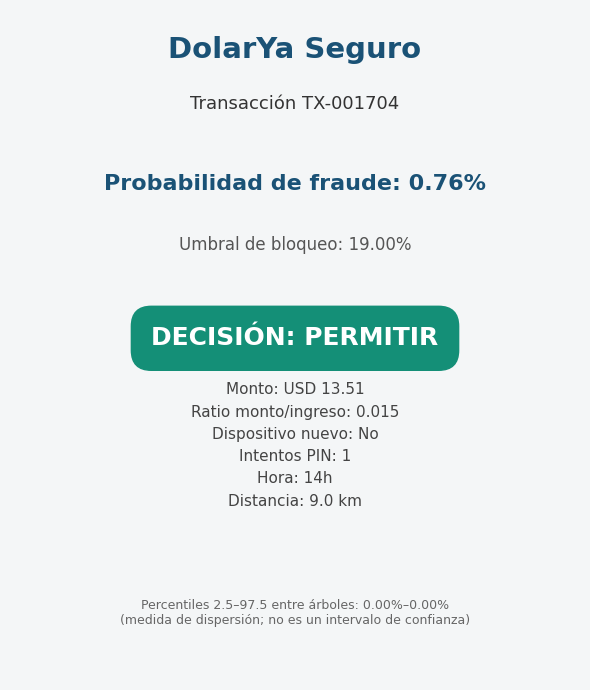

Transacción presentada: TX-001704
Probabilidad estimada: 0.0076
Umbral aplicado: 0.1900
Decisión final: PERMITIR


In [8]:
# ✏️ Pantalla de la app

idx = 0
proba_ejemplo = float(y_proba_rf[idx])
transaccion = X_test.iloc[idx]

# Identificador original de la transacción del conjunto de prueba.
if 'evento_id' in df.columns:
    id_transaccion = str(df.loc[X_test.index[idx], 'evento_id'])
else:
    id_transaccion = f'TX-{idx:05d}'

# La decisión se calcula con el mismo umbral seleccionado en validación.
decision = 'BLOQUEAR' if proba_ejemplo >= mejor_umbral else 'PERMITIR'
color_decision = COLOR_ALERTA if decision == 'BLOQUEAR' else '#148F77'

# Dispersión de las predicciones de los árboles para este mismo caso.
predicciones_arboles_ejemplo = np.array([
    arbol.predict_proba(X_test.iloc[[idx]])[0, 1]
    for arbol in rf.estimators_
])
percentil_inferior = float(np.percentile(predicciones_arboles_ejemplo, 2.5))
percentil_superior = float(np.percentile(predicciones_arboles_ejemplo, 97.5))

fig, ax = plt.subplots(figsize=(6, 7))
fig.patch.set_facecolor('#F4F6F7')
ax.set_facecolor('#F4F6F7')
ax.axis('off')

ax.text(
    0.5, 0.94, f'{NOMBRE_APP} Seguro',
    fontsize=21, ha='center', va='center', color=COLOR_PRINCIPAL, weight='bold'
)
ax.text(
    0.5, 0.86, f'Transacción {id_transaccion}',
    fontsize=13, ha='center', va='center', color='#333333'
)
ax.text(
    0.5, 0.74, f'Probabilidad de fraude: {proba_ejemplo:.2%}',
    fontsize=16, ha='center', va='center', color=COLOR_PRINCIPAL, weight='bold'
)
ax.text(
    0.5, 0.65, f'Umbral de bloqueo: {mejor_umbral:.2%}',
    fontsize=12, ha='center', va='center', color='#555555'
)
ax.text(
    0.5, 0.51, f'DECISIÓN: {decision}',
    fontsize=18, ha='center', va='center', color='white', weight='bold',
    bbox=dict(boxstyle='round,pad=0.8', facecolor=color_decision, edgecolor=color_decision)
)

ax.text(
    0.5, 0.35,
    f'Monto: USD {transaccion["monto"]:.2f}\n'
    f'Ratio monto/ingreso: {transaccion["ratio"]:.3f}\n'
    f'Dispositivo nuevo: {"Sí" if transaccion["dispositivo_nuevo"] == 1 else "No"}\n'
    f'Intentos PIN: {transaccion["intentos_pin"]:.0f}\n'
    f'Hora: {transaccion["hora"]:.0f}h\n'
    f'Distancia: {transaccion["distancia_km"]:.1f} km',
    fontsize=11, ha='center', va='center', color='#444444', linespacing=1.6
)

ax.text(
    0.5, 0.10,
    'Percentiles 2.5–97.5 entre árboles: '
    f'{percentil_inferior:.2%}–{percentil_superior:.2%}\n'
    '(medida de dispersión; no es un intervalo de confianza)',
    fontsize=9, ha='center', va='center', color='#666666'
)

plt.tight_layout()
plt.savefig('pantalla_app.png', bbox_inches='tight', dpi=300)
plt.show()

print(f'Transacción presentada: {id_transaccion}')
print(f'Probabilidad estimada: {proba_ejemplo:.4f}')
print(f'Umbral aplicado: {mejor_umbral:.4f}')
print(f'Decisión final: {decision}')

---
## 6. Ficha del modelo (4 pts)
Ejecute y suba el archivo descargado a `proyecto/` en GitHub (**Add file → Upload files**).

In [9]:
# ✏️ Ficha del modelo

mejor_modelo = 'Random Forest'

# Las métricas se calculan en el conjunto de prueba.
# La exactitud balanceada usa el umbral seleccionado con validación.
metricas_finales = {
    'auc': float(roc_auc_score(y_test, y_proba_rf)),
    'exactitud_balanceada': float(
        balanced_accuracy_score(y_test, y_pred_rf_umbral)
    ),
    'brier': float(brier_score_loss(y_test, y_proba_rf))
}

ficha = curso.ficha_modelo(
    GRUPO,
    PROBLEMA,
    modelo=mejor_modelo,
    metricas=metricas_finales,
    hiperparametros={
        'n_estimators': 100,
        'max_depth': 10,
        'class_weight': 'balanced',
        'umbral_decision': float(mejor_umbral),
        'random_state': 42,
        'particion_externa': '70/30 estratificada',
        'validacion_interna': '80/20 del bloque de entrenamiento'
    }
)

{
  "grupo": "Grupo 3",
  "problema": "fraude",
  "modelo": "Random Forest",
  "metricas": {
    "auc": 0.9029551209525348,
    "exactitud_balanceada": 0.867760357739346,
    "brier": 0.04626621211278313
  },
  "hiperparametros": {
    "n_estimators": 100,
    "max_depth": 10,
    "class_weight": "balanced",
    "umbral_decision": 0.19,
    "random_state": 42,
    "particion_externa": "70/30 estratificada",
    "validacion_interna": "80/20 del bloque de entrenamiento"
  },
  "semilla": 42,
  "semilla_datos": 177005,
  "fecha": "2026-11-18 23:13",
  "versiones": {
    "python": "3.13.18",
    "numpy": "2.4.6",
    "pandas": "2.2.3",
    "scikit-learn": "1.6.1"
  }
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## 7. Plantilla del informe (`proyecto/README.md`)
En GitHub abra `proyecto/README.md` → **lápiz (Edit)** → reemplace todo por este texto completado con sus cifras → **Commit changes**:

```
# Sistema de decisión para detección de fraude en DolarYa — Grupo 3

**Integrantes:** Grace Castillo, Santiago Segovia y Marcelo Verdezoto  
**Problema:** detección de transacciones fraudulentas.

## 1. Problema y datos

El objetivo es identificar transacciones potencialmente fraudulentas para apoyar la decisión de bloqueo. Se analizaron **2,996 transacciones**, con una tasa de fraude de **10.28%**. Se recalculó `ratio` como monto dividido para ingreso mensual y se creó `madrugada` para identificar transacciones entre las 00:00 y las 05:59.

## 2. Modelos comparados

Los modelos se evaluaron sobre el mismo conjunto de prueba. La exactitud balanceada de esta tabla utiliza un umbral de clasificación de 0.50. Un AUC y una exactitud balanceada más altos son mejores; un Brier más bajo es mejor.

| Modelo | AUC | Exactitud balanceada | Brier |
|---|---:|---:|---:|
| Random Forest | 0.902955 | 0.770359 | 0.046266 |
| Red Neuronal | 0.903911 | 0.743185 | 0.048513 |
| XGBoost | 0.890011 | 0.841967 | 0.051860 |
| Regresión Logística | 0.896490 | 0.834498 | 0.119253 |

**Modelo seleccionado para la explicación y decisión de negocio:** Random Forest.

## 3. Explicabilidad

El análisis SHAP se aplicó al modelo Random Forest. Las cinco variables con mayor importancia SHAP media en esta ejecución son: **dispositivo_nuevo, ratio, distancia_km, monto, intentos_pin**. SHAP describe la contribución de las variables a las predicciones del modelo; no implica causalidad.

La variabilidad de predicciones entre árboles se reporta como dispersión entre estimadores, no como intervalo de confianza estadístico.

## 4. Recomendación de negocio

El umbral se seleccionó usando el conjunto de validación, sin optimizarlo sobre el conjunto de prueba.

- **Umbral de bloqueo seleccionado:** 0.19.
- **Costo en el conjunto de prueba con el modelo:** USD 2,632.82.
- **Costo en el conjunto de prueba sin modelo:** USD 14,825.85.
- **Ahorro estimado en el conjunto de prueba:** USD 12,193.03.

La matriz de costos considera USD 5.00 por cada transacción legítima bloqueada y el monto de cada transacción fraudulenta no detectada como costo de falso negativo.

## 5. Limitaciones y próximos pasos

- Los datos del proyecto son simulados; los resultados no garantizan el mismo desempeño con transacciones reales.
- La evaluación económica depende de los costos asumidos para falsos positivos y falsos negativos.
- El umbral debe revisarse cuando cambien los patrones de fraude o los costos de operación.
- Antes de implementar el modelo en producción, se requiere validación con datos reales, monitoreo de deriva (data drift) y seguimiento de falsos positivos y falsos negativos.

```